# Formulas and Categorical Data

A model formula, like `y ~ x1 + x2 + C(region)`, describes a model in terms of the columns of a data frame, rather than a matrix of numbers. `py-glm` uses [formulaic](https://matthewwardrop.github.io/formulaic/) to turn a formula and a data frame into a design matrix, and in return we get:

- **names** for every coefficient, and an intercept, without building them by hand,
- **encodings** of categorical variables as indicator columns, and
- **transforms**, such as centering, interactions, and splines, written inline.

Just as importantly, the model *remembers* how it turned its training data into a design matrix, and turns any new data into a design matrix the same way. This notebook works through each of these, using data simulated with `py-glm`'s `datasets` module.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glm.datasets import make_frame
from glm.families import Gaussian, Poisson
from glm.glm import GLM

As in the families notebook, this helper lines a fit model's estimates up against the true coefficients, and each simulation gets its own seed, so the results don't depend on the order the cells are run in.

In [2]:
def compare(model, truth):
    """A fit model's estimates next to the true coefficients."""
    table = pd.DataFrame(
        {
            "estimate": model.coef_,
            "std error": model.coef_standard_error_,
            "truth": truth,
        },
        index=model.X_names,
    )
    table["z"] = (table["estimate"] - table["truth"]) / table["std error"]
    return table.round(3)

## Formulas versus arrays

Here are counts, from a Poisson model with two continuous predictors and a categorical variable, `region`, with three levels:

In [3]:
sim = make_frame(
    Poisson(),
    n_samples=2000,
    n_uncorrelated=2,
    categorical={"region": 3},
    coef_range=(-0.5, 0.5),
    rng=np.random.default_rng(1),
)
sim.data.head()

,x1,x2,region,y
0,0.345584,0.821618,a,1
1,0.330437,-1.303157,c,0
2,0.905356,0.446375,c,0
3,-0.536953,0.581118,c,0
4,0.364572,0.294132,b,0


With a formula, we fit the model straight from the data frame. The formula describes which column is the response (the left hand side), which are the predictors (the right hand side), and how to treat the predictors (for example, the `C(...)` notation encodes a categorical):

In [4]:
formula_model = GLM(Poisson()).fit(sim.data, formula="y ~ x1 + x2 + C(region)")
formula_model.X_names

['Intercept', 'x1', 'x2', 'C(region)[T.b]', 'C(region)[T.c]']

Without a formula, we must build the design matrix ourselves: a column of ones for the intercept, the continuous predictors, and an indicator column for each level of `region` (leaving out one). Fitting a model gives exactly the same estimates, but with generic names:

In [5]:
X = np.column_stack(
    [
        np.ones(len(sim.data)),
        sim.data["x1"],
        sim.data["x2"],
        sim.data["region"] == "b",
        sim.data["region"] == "c",
    ]
).astype(np.float64)
array_model = GLM(Poisson()).fit(X, sim.data["y"].to_numpy())

print("Generic Names:", array_model.X_names)
print("Both models produce the same estimates?", np.allclose(array_model.coef_, formula_model.coef_))

Generic Names: ['Intercept', 'X1', 'X2', 'X3', 'X4']
Both models produce the same estimates? True


## Reading categorical coefficients

Why only two indicator columns for three regions? With an intercept in the model, indicators for all three levels would be redundant: they always sum to one, the intercept column. This leads to an *overdetermined* model, multiple values of the coefficients lead to exactly the same predictions.

The common solutions is to take one level, here the first, `a`, as the *reference level*, it gets no column of its own. Its effect is absorbed into the intercept, and each remaining coefficient is a *contrast*: the difference between that level and the reference level. `make_frame`'s true coefficients use the same coding, so we can compare them directly:

In [6]:
compare(formula_model, sim.coef)

,estimate,std error,truth,z
Intercept,-0.033,0.040,-0.090,1.422
x1,-0.379,0.023,-0.380,0.062
x2,-0.296,0.023,-0.306,0.435
C(region)[T.b],-0.180,0.056,-0.132,-0.863
C(region)[T.c],-0.325,0.057,-0.272,-0.943


With the Poisson family's log link, differences on the linear predictor's scale are ratios on the scale of the mean. So `exp(β)` for a region's coefficient is a *rate ratio*: how many times the expected count of an observation in that region is tmies the expected count of an otherwise identical observation in region `a` (the reference):

In [7]:
region_terms = ["C(region)[T.b]", "C(region)[T.c]"]
rate_ratios = np.exp(pd.Series(formula_model.coef_, index=formula_model.X_names)[region_terms])
pd.DataFrame({"estimated rate ratio": rate_ratios, "true rate ratio": np.exp(sim.coef[region_terms])}).round(3)

,estimated rate ratio,true rate ratio
C(region)[T.b],0.835,0.876
C(region)[T.c],0.722,0.762


## Predicting on new data

A model fit with a formula needs new data in the same form as its training data: a data frame with the same columns. It then turns that data into a design matrix exactly as it did its training data, which matters more than it might seem.

Take `center(x1)`, which subtracts the mean of `x1`. Our `x1` already has a mean near zero, so to see centering do something, shift it to sit far from zero, like an age or a temperature might. Centering changes only the intercept: without it, the intercept describes `x1 = 0`, far from any of the data, and with it, the average `x1`. The slopes are untouched:

In [8]:
shifted = sim.data.assign(x1=sim.data["x1"] + 10)
uncentered_model = GLM(Poisson()).fit(shifted, formula="y ~ x1 + x2 + C(region)")
centered_model = GLM(Poisson()).fit(shifted, formula="y ~ center(x1) + x2 + C(region)")
pd.DataFrame(
    {"uncentered": uncentered_model.coef_, "centered": centered_model.coef_},
    index=["Intercept", "x1", "x2", "C(region)[T.b]", "C(region)[T.c]"],
).round(3)

,uncentered,centered
Intercept,3.752,-0.028
x1,-0.379,-0.379
x2,-0.296,-0.296
C(region)[T.b],-0.180,-0.180
C(region)[T.c],-0.325,-0.325


For a new observation, *which* mean should the model subtract?

It must be the *training* data's mean of `x1`: the new data's own mean would be *mean*ingless. Consider the extreme case of a single observation: centering would make every centered value zero (we subtract the mean of a single observation from that observation itself). In the more general case, computing the mean of data at inference time is a form of [data leakage](https://en.wikipedia.org/wiki/Leakage_(machine_learning)), which is a common source of subtle errors in predictive data analysis.

The `centered_model` stores the training mean, along with everything else it learned about the formula from the training data, and uses it when making predictions:

In [9]:
new = pd.DataFrame({"x1": [11.0], "x2": [0.5], "region": ["c"]})

β = pd.Series(centered_model.coef_, index=centered_model.X_names)
by_hand = np.exp(
    β["Intercept"]
    # Manually centering with the training mean.
    + β["center(x1)"] * (11.0 - shifted["x1"].mean())
    + β["x2"] * 0.5
    + β["C(region)[T.c]"]
)

print(f"Training mean of x1: {shifted['x1'].mean():.3f}")
print(f"Model Prediction: {centered_model.predict(new)[0]:.4f}")
print(f"By hand, centering with the training mean: {by_hand:.4f}")

Training mean of x1: 9.985
Model Prediction: 0.4125
By hand, centering with the training mean: 0.4125


The same goes for categorical variables. The new observation above is in region `c` only, but it's still encoded with the training data's columns, one for each of regions `b` and `c`, with region `a` as the reference. Encoding the new data from scratch would find only one level, and produce a design matrix with the wrong number of columns.

## Interactions

So far, each predictor has the same effect in every region. An *interaction* lets the effect of one predictor depend on another. Here's data, simulated by hand, in which the slope of a continuous predictor `x` differs by region:

In [10]:
rng = np.random.default_rng(2)
n = 1000

data = pd.DataFrame({
    "x": rng.normal(size=n), 
    "region": rng.choice(["a", "b", "c"], size=n)
})

# Intercepts and slopes that vary by reigon
intercepts = {"a": 1.0, "b": 0.0, "c": 2.0}
slopes = {"a": 0.5, "b": 1.25, "c": -0.5}

data["y"] = (
    data["region"].map(intercepts)
    + data["region"].map(slopes) * data["x"]
    + rng.normal(size=n)
)

Interactions are specified in model formulas using the `*` operator.

The formula `x * C(region)` expands to `x + C(region) + x:C(region)`: the main effects of `x` and `region`, and their interaction. With reference coding, the coefficient of `x` is the slope in the reference region `a`, and each interaction coefficient, like `x:C(region)[T.b]`, is how much region `b`'s slope *differs* from region `a`'s, the same contrast idea as before. The intercept and region coefficients work the same way:

In [11]:
interaction_model = GLM(Gaussian()).fit(data, formula="y ~ x * C(region)")

truth = pd.Series(
    {
        "Intercept": intercepts["a"],
        "x": slopes["a"],
        "C(region)[T.b]": intercepts["b"] - intercepts["a"],
        "C(region)[T.c]": intercepts["c"] - intercepts["a"],
        "x:C(region)[T.b]": slopes["b"] - slopes["a"],
        "x:C(region)[T.c]": slopes["c"] - slopes["a"],
    }
)
compare(interaction_model, truth)

,estimate,std error,truth,z
Intercept,0.992,0.053,1.00,-0.152
x,0.498,0.050,0.50,-0.031
C(region)[T.b],-1.081,0.076,-1.00,-1.072
C(region)[T.c],1.058,0.074,1.00,0.780
x:C(region)[T.b],0.688,0.074,0.75,-0.844
x:C(region)[T.c],-0.943,0.073,-1.00,0.778


So each region's individual slope is the reference slope plus its difference:

In [12]:
β = pd.Series(interaction_model.coef_, index=interaction_model.X_names)

estimated_slopes = {
    "a": β["x"],
    "b": β["x"] + β["x:C(region)[T.b]"],
    "c": β["x"] + β["x:C(region)[T.c]"],
}
pd.DataFrame({"estimated slope": estimated_slopes, "true slope": slopes}).round(3)

,estimated slope,true slope
a,0.498,0.50
b,1.186,1.25
c,-0.445,-0.50


Plotting the data with the fitted lines, one per region, shows how the intercept and slope varies to fit the observed data:

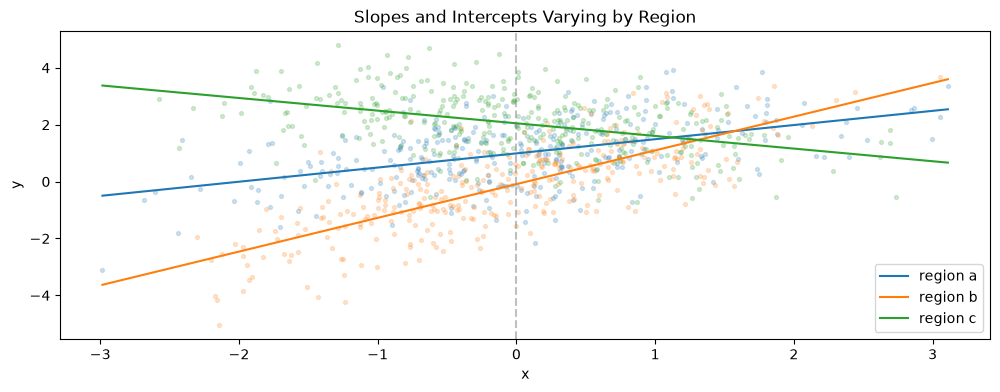

In [13]:
def plot_fitted_lines(ax, model, data):
    """Scatter the data, and draw the model's fitted line in each region."""
    grid = np.linspace(data["x"].min(), data["x"].max(), 50)
    for i, region in enumerate(["a", "b", "c"]):
        in_region = data["region"] == region
        ax.scatter(data.loc[in_region, "x"], data.loc[in_region, "y"], color=f"C{i}", alpha=0.2, s=8)
        line = pd.DataFrame({"x": grid, "region": region})
        ax.plot(grid, model.predict(line), color=f"C{i}", label=f"region {region}")
    ax.axvline(0.0, color='grey', alpha=0.5, linestyle='--')
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Slopes and Intercepts Varying by Region")
    ax.legend()
    return ax

fig, ax = plt.subplots(figsize=(12, 4))
plot_fitted_lines(ax, interaction_model, data);

## Splines

A coefficient per predictor assumes each predictor's effect on the linear predictor is a straight line. A *spline* relaxes that: it replaces a single predictor with several basis functions, smooth curves that summed together can approximate any smooth shape, and the model fits a coefficient for each. `formulaic`'s `cs(x, df=10)` gives ten [natural cubic spline](https://en.wikipedia.org/wiki/Spline_(mathematics)) basis functions.

Here are counts whose log-rate is a smooth, non-linear function of `x`:

In [14]:
rng = np.random.default_rng(3)
n = 1000
data = pd.DataFrame({"x": rng.uniform(0, 12, size=n)})

def true_rate(x):
    return 0.5 + x * (np.sin(1.25*x) + 1)

data["y"] = rng.poisson(true_rate(data["x"]))

In [15]:
spline_model = GLM(Poisson()).fit(data, formula="y ~ cs(x, df=10)")
spline_model.X_names

['Intercept',
 'cs(x, df=10)[1]',
 'cs(x, df=10)[2]',
 'cs(x, df=10)[3]',
 'cs(x, df=10)[4]',
 'cs(x, df=10)[5]',
 'cs(x, df=10)[6]',
 'cs(x, df=10)[7]',
 'cs(x, df=10)[8]',
 'cs(x, df=10)[9]',
 'cs(x, df=10)[10]']

The individual coefficients don't mean much on their own; the fitted curve does. Here it is, against the true rate, and the data's average count in narrow bins of `x`:

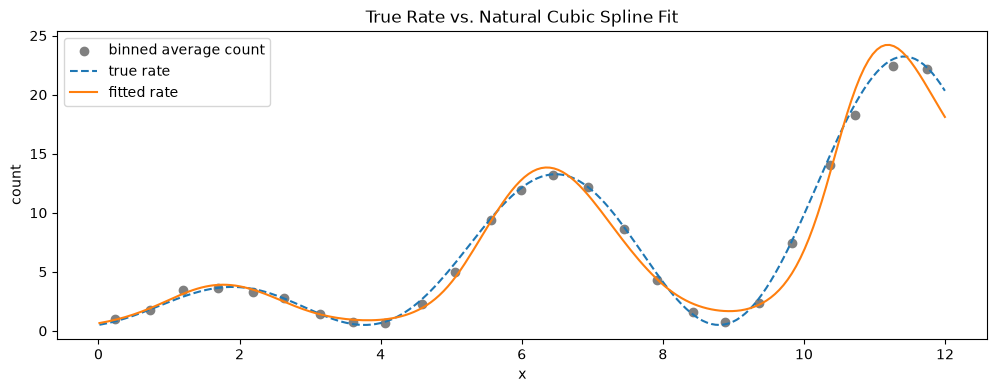

In [16]:
def plot_spline_fit(ax, model, data):
    """Binned averages of the data, the true rate, and the model's fit."""
    bins = pd.cut(data["x"], bins=25)
    binned = data.groupby(bins, observed=True).agg(x=("x", "mean"), y=("y", "mean"))
    ax.scatter(binned["x"], binned["y"], color="grey", label="binned average count")
    grid = np.linspace(data["x"].min(), data["x"].max(), 200)
    ax.plot(grid, true_rate(grid), color="C0", linestyle="--", label="true rate")
    ax.plot(grid, model.predict(pd.DataFrame({"x": grid})), color="C1", label="fitted rate")
    ax.set_xlabel("x")
    ax.set_ylabel("count")
    ax.set_title("True Rate vs. Natural Cubic Spline Fit")
    ax.legend()
    return ax

fig, ax = plt.subplots(figsize=(12, 4))
plot_spline_fit(ax, spline_model, data);

Like `center`, the spline is learned from the training data: its *knots*, the points where the cubic pieces join, are placed at quantiles of the training `x`, and stored. So predictions on new data use the same basis functions as the fit, even for new data covering only part of the range.

Natural cubic splines also extrapolate sensibly. They're constrained to have a second derivative of zero at the boundary knots, and to be straight lines beyond them, so outside the range of the data, the fit extends linearly on the scale of the link: here, the log of the rate. That rules out the wild swings a polynomial can make outside its data. But a straight line on the log scale is an exponential curve on the scale of the counts, which simply continues whatever trend the fit had at the edge of the data. Here's the fit over a range wider than the data's:

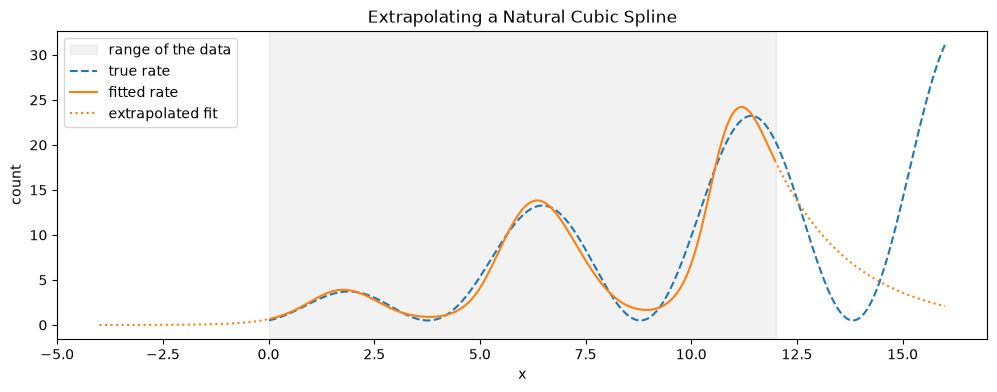

In [17]:
def plot_extrapolation(ax, model, data, lower, upper):
    """The fit over a range wider than the data's: within the data's range,
    extrapolated beyond it, and the true rate, defined for x >= 0."""
    grid = np.linspace(lower, upper, 400)
    fitted = model.predict(pd.DataFrame({"x": grid}))
    low, high = data["x"].min(), data["x"].max()
    ax.axvspan(low, high, color="grey", alpha=0.1, label="range of the data")
    true_grid = grid[grid >= 0]
    ax.plot(true_grid, true_rate(true_grid), color="C0", linestyle="--", label="true rate")
    inside = (grid >= low) & (grid <= high)
    ax.plot(grid[inside], fitted[inside], color="C1", label="fitted rate")
    ax.plot(grid[grid < low], fitted[grid < low], color="C1", linestyle=":", label="extrapolated fit")
    ax.plot(grid[grid > high], fitted[grid > high], color="C1", linestyle=":")
    ax.set_xlabel("x")
    ax.set_ylabel("count")
    ax.set_title("Extrapolating a Natural Cubic Spline")
    ax.legend()
    return ax


fig, ax = plt.subplots(figsize=(12, 4))
plot_extrapolation(ax, spline_model, data, lower=-4, upper=16);

The extrapolation is smooth and stable, but it can only continue the trend at each edge of the data. To the left, the fit decays toward zero, continuing its fall toward the lower boundary. To the right, it continues the downturn after the last peak, decaying exponentially, while the true rate dips and then climbs past 30. Natural splines make extrapolation *well behaved*, but not necessarily *correct*: no model can know what the data would have done where there are none.

## Missing values

If any of the columns a formula uses has a missing value, `fit` raises an error, rather than silently dropping the row:

In [18]:
incomplete = sim.data.copy()
incomplete.loc[3, "x1"] = np.nan
try:
    GLM(Poisson()).fit(incomplete, formula="y ~ x1 + x2 + C(region)")
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: Error encountered while checking for nulls in `x1`: `x1` contains null values after evaluation.


Silently dropping rows is a common source of quiet errors: an offset or sample weights passed alongside the data would no longer line up with its rows, and `predict` would return fewer predictions than rows. So handling missing values is left to you: drop the incomplete rows explicitly, or impute them.

In [19]:
complete = incomplete.dropna()
print(f"Dropped {len(incomplete) - len(complete)} incomplete row(s).")
GLM(Poisson()).fit(complete, formula="y ~ x1 + x2 + C(region)").X_names

Dropped 1 incomplete row(s).


['Intercept', 'x1', 'x2', 'C(region)[T.b]', 'C(region)[T.c]']